# Making fonts

A handwritten-style font drawn with stroked paths, used straight away for text, then an icon font of four
icons with its stylesheet and cheatsheet. Compiling needs the `fonts` extra: `pip install 'pysvgwriter[fonts]'`.

    python 20_fonts.py                  writes 20_hand.otf/.ttf, 20_hand.svg, 20_icons.woff/.css,
                                        20_icons.svg and 20_cheatsheet.svg

In [1]:
import svgwriter as svg

Each letter is drawn in y-down drawing units with the baseline at `y=0`: the x-height sits at `y=-40` and
ascenders reach `y=-70`. `scale=10` makes one drawing unit ten font units. Strokes become outline, and
the advance is the outline width plus the side bearings.

In [2]:
PEN = {"fill": "none", "stroke": "black", "stroke_width": 7, "stroke_linecap": "round", "stroke_linejoin": "round"}
BOWL = "C34 -34 26 -40 17 -40 C6 -40 0 -32 0 -20 C0 -8 6 0 17 0 C26 0 34 -8 34 -20"
LETTERS = {
    "h": "M0 -70 V0 M0 -22 C4 -38 26 -42 28 -24 V0",
    "e": "M0 -20 H34 C34 -34 26 -40 17 -40 C6 -40 0 -32 0 -20 C0 -6 10 0 18 0 C26 0 31 -4 33 -8",
    "l": "M5 -70 C3 -40 3 -15 10 0",
    "o": f"M34 -20 {BOWL}",
    "w": "M0 -40 L9 0 L18 -30 L27 0 L36 -40",
    "r": "M0 -40 V0 M0 -24 C4 -36 14 -42 24 -38",
    "d": f"M34 -70 V0 M34 -20 {BOWL}",
}

hand = svg.FontBuilder(family="Example Hand", scale=10, cap_height=700, x_height=400)
for char, d in LETTERS.items():
    hand.glyph(char, svg.path(d, **PEN), left=60, right=60)
hand.glyph(" ", advance=300)
hand.kern("w", "o", -60)
hand.kern("r", "l", -40)
hand.save("20_hand.otf")
hand.save("20_hand.ttf")

WindowsPath('20_hand.ttf')

`typeface()` loads the font back as an `svg.Typeface`, so text uses it at once and renders without
installing anything; `embed_fonts()` carries it inside the saved SVG.

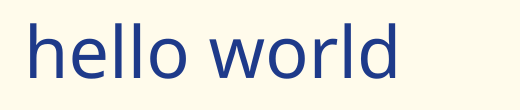

In [3]:
written = svg.Document(520, 110)
written.rect(0, 0, 520, 110, fill="#fffbeb")
written.text("hello world", x=24, y=78, font_family=hand.typeface(), font_size=72, fill="#1e3a8a")
written.embed_fonts()
written.save("20_hand.svg")
written

Icons get private-use code points from U+E000 in the order they are added, and each drawing is scaled to
fill the em. `save_css` writes the `@font-face` rule and an `.icon-<name>::before` class per icon.

In [4]:
window = svg.circle(12, 9, 2.2)
icons = svg.FontBuilder(family="Example Icons")
icons.icon("rocket", svg.group(
    svg.path("M12 2 C16 5 17 10 16 16 H8 C7 10 8 5 12 2 Z") - window,
    svg.path("M8 11 L4 17 L8 16 Z"),
    svg.path("M16 11 L20 17 L16 16 Z"),
    svg.path("M10 17 H14 L12 22 Z"),
))
icons.icon("star", svg.paths.star(12, 12, 10))
icons.icon("home", svg.path("M2 11 L12 2 L22 11 V22 H15 V15 H9 V22 H2 Z"))
icons.icon("bell", svg.group(
    svg.path("M6 17 V11 C6 7 8.5 4.5 12 4.5 C15.5 4.5 18 7 18 11 V17 L20 19 H4 Z"),
    svg.circle(12, 21, 2),
))
icons.save("20_icons.woff")
icons.save_css("20_icons.css", font="20_icons.woff")
print(icons.css("20_icons.woff").splitlines()[-1])

.icon-bell::before { content: "\e003"; }


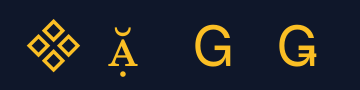

In [5]:
icon_face = icons.typeface()
row = svg.Document(360, 90)
row.rect(0, 0, 360, 90, fill="#0f172a")
for index, char in enumerate(icons.icons.values()):
    row.text(char, x=24 + index * 84, y=66, font_family=icon_face, font_size=56, fill="#fbbf24")
row.embed_fonts()
row.save("20_icons.svg")
row

The cheatsheet draws every glyph with its name and code point.

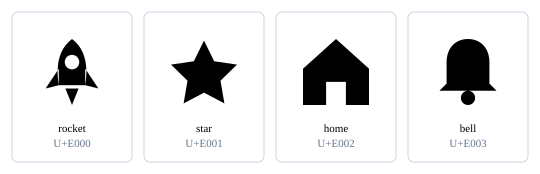

In [6]:
sheet = icons.cheatsheet(columns=4)
sheet.save("20_cheatsheet.svg")
sheet